<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/DT/notebooks/DT_model_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import Library

In [8]:
import pandas as pd
from pathlib import Path
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

##LOAD AND PREPROCESS DATA

In [18]:
from google.colab import files

uploaded = files.upload()
FILE = list(uploaded.keys())[0]



Saving Maths operation data.xlsx to Maths operation data (1).xlsx


In [19]:
df = pd.read_excel(FILE)
print('Rows, columns:', df.shape)
df.head(10)

Rows, columns: (297, 7)


,No,Operation_Type,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests,Student_Label
0,1,Addition,2.10,2.10,0,0,Normal
1,2,Addition,1.89,1.89,0,0,Normal
2,3,Addition,2.62,2.62,0,0,Normal
3,4,Addition,3.07,3.07,0,0,Normal
4,5,Division,8.20,8.20,0,0,Normal
5,6,Division,44.15,44.15,1,0,Normal
6,7,Division,34.86,34.86,0,0,Normal
7,8,Division,13.44,13.44,0,0,Normal
8,9,Subtraction,2.70,2.70,0,0,Normal
9,10,Subtraction,2.57,2.57,0,0,Normal


##Look at the data

In [5]:
print('Missing values:'); print(df.isna().sum().to_string())
print('\nClass counts:'); print(df['Student_Label'].value_counts())
print('\nAverages per class:')
df.groupby('Student_Label')[['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']].mean().round(2)

Missing values:
No                 0
Operation_Type     0
Total_Time         0
Carry_Over_Time    0
Erasure_Count      0
Hint_Requests      0
Student_Label      0

Class counts:
Student_Label
Normal    234
Slow       63
Name: count, dtype: int64

Averages per class:


,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests
Student_Label,,,,
Normal,10.54,9.17,0.05,0.00
Slow,54.30,44.29,0.60,0.65


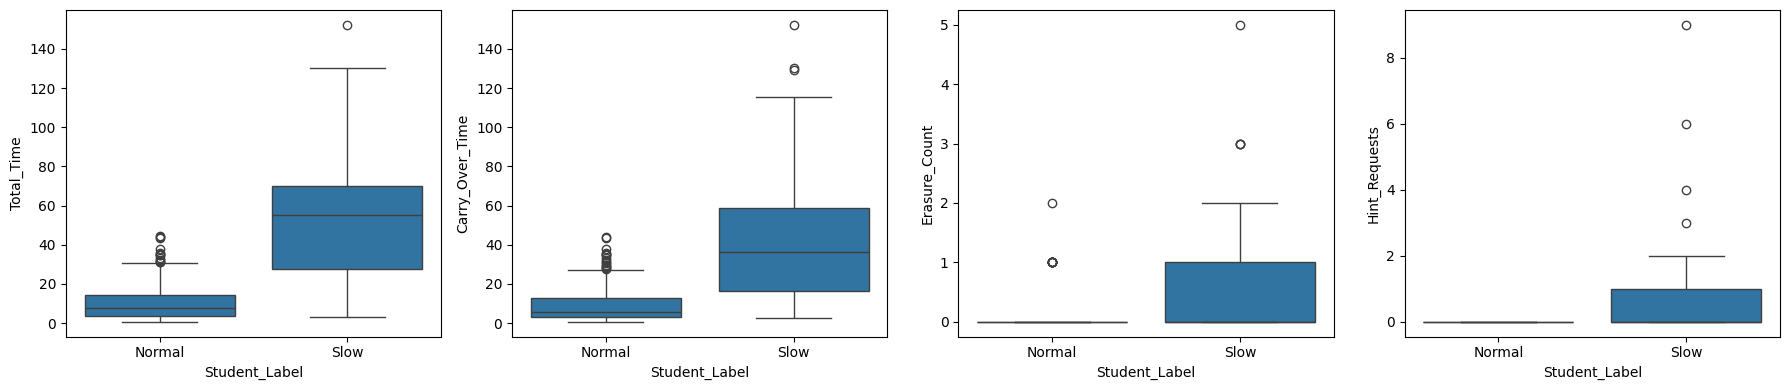

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']):
    sns.boxplot(data=df, x='Student_Label', y=col, ax=a)
plt.tight_layout(); plt.show()

##Feature engineering

In [22]:
USE_HINTS = True      # <- change to False and re-run to test without Hint_Requests

data = df.copy()
data['Slow'] = (data['Student_Label'] == 'Slow').astype(int)      # 1 = Slow, 0 = Normal
data['Carry_Ratio'] = data['Carry_Over_Time'] / data['Total_Time']
data['Non_Carry_Time'] = data['Total_Time'] - data['Carry_Over_Time']

num_cols = ['Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time']
if USE_HINTS: num_cols.append('Hint_Requests')
cat_cols = ['Operation_Type']
FEATURES = num_cols + cat_cols

X = data[FEATURES]
y = data['Slow']
print('Features used:', FEATURES)

Features used: ['Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time', 'Hint_Requests', 'Operation_Type']


##Split into train (80%) and test (20%)

In [24]:
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Slow share  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train rows: 237 | Test rows: 60
Slow share  train: 0.211  test: 0.217


##  Train the Decision Tree (first version)

In [49]:
def make_model(**tree_params):
    prep = ColumnTransformer([('op', OneHotEncoder(handle_unknown='ignore'), cat_cols)], remainder='passthrough')
    tree = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE, **tree_params)
    return Pipeline([('prep', prep), ('tree', tree)])

dt = make_model(max_depth=6)
dt.fit(X_train, y_train)
print('Trained!')

Trained!


Evaluate on the test set
| Metric | Meaning (for the Slow class) |
|---|---|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of the students predicted Slow, how many really are Slow |
| **Recall** | Of the truly Slow students, how many we caught (missed ones hurt most) |
| **F1** | Balance between Precision and Recall |
| **Specificity** | Of the truly Normal students, how many we correctly called Normal |
| **ROC-AUC** | How well the model ranks Slow above Normal (1.0 = perfect, 0.5 = guessing) |
| **MCC** | Overall quality for imbalanced data (1 = perfect, 0 = random) |

In [50]:
def evaluate(model, X_, y_, title=''):
    pred = model.predict(X_)
    prob = model.predict_proba(X_)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_, pred).ravel()
    m = {'Accuracy': accuracy_score(y_, pred), 'Balanced Accuracy': balanced_accuracy_score(y_, pred),
         'Precision': precision_score(y_, pred, zero_division=0), 'Recall': recall_score(y_, pred),
         'F1': f1_score(y_, pred), 'Specificity': tn / (tn + fp), 'ROC-AUC': roc_auc_score(y_, prob),
         'MCC': matthews_corrcoef(y_, pred)}
    print(title); display(pd.Series(m, name='score').round(3).to_frame())
    print(f'TP={tp} (slow caught)  FN={fn} (slow missed)  FP={fp} (false alarm)  TN={tn}')
    return m, pred, prob

m1, pred1, prob1 = evaluate(dt, X_test, y_test, '=== Test-set results (first tree) ===')

=== Test-set results (first tree) ===


,score
Accuracy,0.917
Balanced Accuracy,0.891
Precision,0.786
Recall,0.846
F1,0.815
Specificity,0.936
ROC-AUC,0.913
MCC,0.762


TP=11 (slow caught)  FN=2 (slow missed)  FP=3 (false alarm)  TN=44


              precision    recall  f1-score   support

      Normal       0.96      0.94      0.95        47
        Slow       0.79      0.85      0.81        13

    accuracy                           0.92        60
   macro avg       0.87      0.89      0.88        60
weighted avg       0.92      0.92      0.92        60



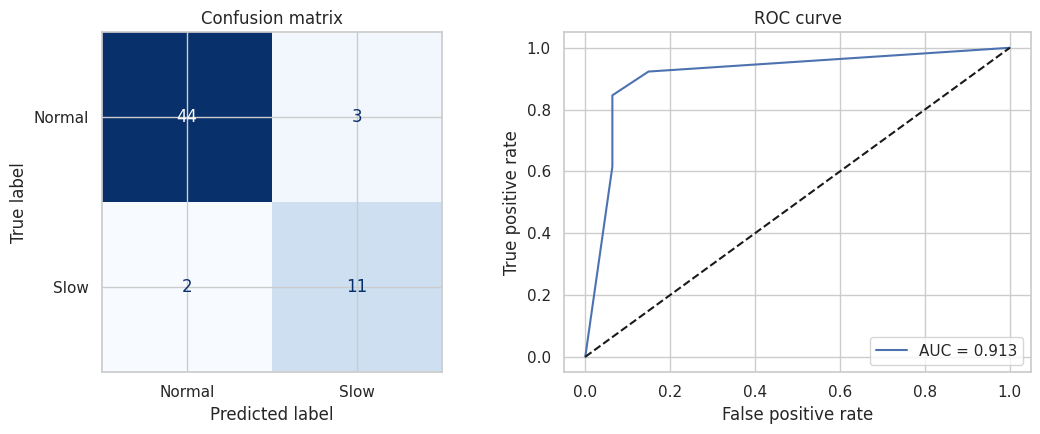

In [51]:
print(classification_report(y_test, pred1, target_names=['Normal', 'Slow']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred1), display_labels=['Normal', 'Slow']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')
fpr, tpr, _ = roc_curve(y_test, prob1)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob1):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()

In [52]:
# Overfitting check: a big gap between train and test means the tree memorised the training data
print('Train accuracy:', round(accuracy_score(y_train, dt.predict(X_train)), 3))
print('Test  accuracy:', round(accuracy_score(y_test,  dt.predict(X_test)), 3))
print('Train F1      :', round(f1_score(y_train, dt.predict(X_train)), 3))
print('Test  F1      :', round(f1_score(y_test,  dt.predict(X_test)), 3))

Train accuracy: 0.949
Test  accuracy: 0.917
Train F1      : 0.882
Test  F1      : 0.815
